# Predicting Student Final Exam Grades
### Decision Tree Regression, Random Forests, and a Confusion Matrix

**Our question:** Can we predict a student's final mathematics grade using their earlier grades and study habits?

By the end, we will:
1. Load and explore a real dataset.
2. Train a **decision tree regressor** with `max_depth=3`.
3. Evaluate its predictions with **MAE, RMSE, and R²**.
4. Draw the tree and inspect **feature importance**.
5. Compare it with a **random forest**.
6. Build a separate **pass/fail classifier** so we can see a **confusion matrix**.

> **Important:** Predicting an exact grade (e.g., 14.2/20) is **regression**. Predicting Pass or Fail is **classification**. A confusion matrix is for classification, not numeric regression.

**Dataset:** UCI [Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance), mathematics course, 395 students. Grades range from **0 to 20**.

## 1. Import our tools

We only need a few standard Python data-science libraries. If something is missing, install it in a notebook cell with:

`%pip install pandas numpy matplotlib scikit-learn`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, ConfusionMatrixDisplay
)

## 2. Load the real student data

The file uses **semicolons** (`;`) between columns, not commas.

- If you have `student-mat.csv` next to this notebook, it will use that file.
- Otherwise, it downloads the same dataset from a public GitHub mirror of the UCI data. **Internet is needed for the first download.**


In [2]:
# Direct CSV mirror of the UCI mathematics dataset.
url = "https://raw.githubusercontent.com/rupakc/UCI-Data-Analysis/master/Student%20Dataset/Student/student-mat.csv"

try:
    students = pd.read_csv("student-mat.csv", sep=";")
    print("Loaded student-mat.csv from this folder.")
except FileNotFoundError:
    students = pd.read_csv(url, sep=";")
    print("Downloaded the UCI student dataset.")

print("Students:", len(students))
students.head().T

Downloaded the UCI student dataset.
Students: 395


,0,1,2,3,4
school,GP,GP,GP,GP,GP
sex,F,F,F,F,F
age,18,17,15,15,16
address,U,U,U,U,U
famsize,GT3,GT3,LE3,GT3,GT3
Pstatus,A,T,T,T,T
Medu,4,1,1,4,3
Fedu,4,1,1,2,3
Mjob,at_home,at_home,at_home,health,other
Fjob,teacher,other,other,services,other


## 3. What are we predicting?

Our target is **`G3`**, the final mathematics grade (**0–20**).

Here is the distribution of those grades. Each bar shows how many students received a particular grade.

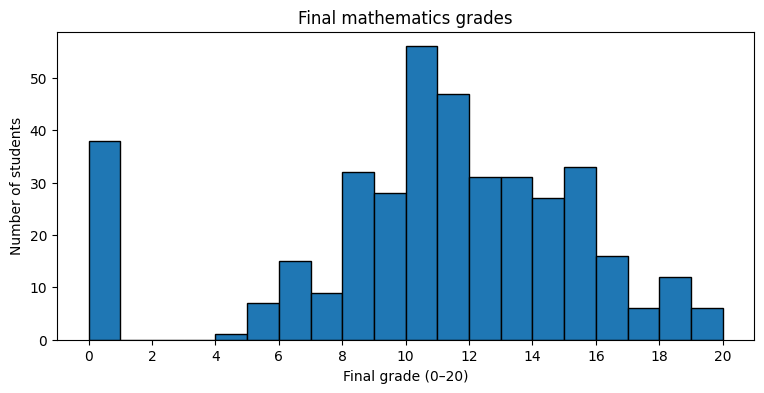

In [3]:
# See how the final grades are distributed.
plt.figure(figsize=(9, 4))
plt.hist(students["G3"], bins=20, edgecolor="black")
plt.title("Final mathematics grades")
plt.xlabel("Final grade (0–20)")
plt.ylabel("Number of students")
plt.xticks(range(0, 21, 2))
plt.show()

array([[<Axes: title={'center': 'final_grade_zero_to_onehundred'}>]],
      dtype=object)

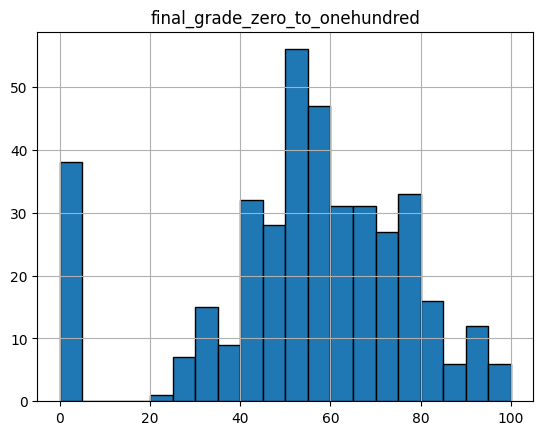

In [4]:
students["final_grade_zero_to_onehundred"] = students["G3"] * 5
students.hist(column="final_grade_zero_to_onehundred",bins=20, edgecolor="black")

## 4. Choose Features [link](https://archive.ics.uci.edu/dataset/320/student+performance) to data dictionary and meaning of every column.

We'll keep it simple with **7 numeric columns**:

| Column | Meaning |
|---|---|
| `G1` | First grading-period grade (0–20) |
| `G2` | Second grading-period grade (0–20) |
| `studytime` | Weekly study time (1 = least, 4 = most) |
| `failures` | Number of past class failures |
| `absences` | Number of school absences |
| `goout` | Frequency of going out with friends (1–5) |
| `freetime` | Amount of free time after school (1–5) |

We use `G1` and `G2` because they are available **before** the final grade. If we wanted to predict **at the start of the year**, we would need to remove them.

### All columns and information here. 

In [5]:
students.head().T

,0,1,2,3,4
school,GP,GP,GP,GP,GP
sex,F,F,F,F,F
age,18,17,15,15,16
address,U,U,U,U,U
famsize,GT3,GT3,LE3,GT3,GT3
Pstatus,A,T,T,T,T
Medu,4,1,1,4,3
Fedu,4,1,1,2,3
Mjob,at_home,at_home,at_home,health,other
Fjob,teacher,other,other,services,other


In [6]:
students.school.value_counts()

school
GP    349
MS     46
Name: count, dtype: int64

In [7]:
students.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3',
       'final_grade_zero_to_onehundred'],
      dtype='object')

In [8]:


# X = information we use to make predictions.
features = ["G1", "G2", "studytime", "failures", "absences", "goout", "freetime"]
# features = ["studytime", "failures", "absences", "goout", "freetime"]

X = students[features]

# y = the correct answer we want to predict.
y = students["G3"]

# Check for missing values before training.
print("Missing values per feature:")
print(X.isna().sum())

X.head()

Missing values per feature:
G1           0
G2           0
studytime    0
failures     0
absences     0
goout        0
freetime     0
dtype: int64


,G1,G2,studytime,failures,absences,goout,freetime
0,5,6,2,0,6,4,3
1,5,5,2,0,4,3,3
2,7,8,2,3,10,2,3
3,15,14,3,0,2,2,2
4,6,10,2,0,4,2,3


## 5. Split students into training and test sets

- **80% training:** Our model learns from these students.
- **20% testing:** Students the model hasn't seen while learning.

`random_state=42` makes the split repeatable, so everyone in class gets the same result.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training students:", len(X_train))
print("Testing students:", len(X_test))

Training students: 316
Testing students: 79


## 6. Train our decision tree regressor

A **regression tree** predicts a *number*. Each split asks a yes/no question about one feature.

`max_depth=3` keeps the tree small enough to draw and explain.

In [10]:
# Make a small tree with at most 3 levels of questions.
tree = DecisionTreeRegressor(max_depth=3, random_state=42)

# The model learns only from the training students.
tree.fit(X_train, y_train)

# Predict final grades for unseen students.
tree_predictions = tree.predict(X_test)

# Look at some real grades vs. predicted grades.
comparison = pd.DataFrame({
    "Actual grade": y_test.to_numpy(),
    "Predicted grade": np.round(tree_predictions, 1)
})
comparison.head(10)

,Actual grade,Predicted grade
0,10,9.4
1,12,11.5
2,5,6.6
3,10,9.4
4,9,9.4
5,13,13.0
6,18,18.3
7,6,6.6
8,0,6.5
9,14,13.0


## 7. Draw the whole tree

**How to read it:**
- Start at the **top** node.
- If the condition is **True**, go **left**; otherwise go **right**.
- `samples` = number of *training* students in that node.
- `value` = average final grade of those training students. That's the prediction at a leaf!

The tree below has at most **3 splits from root to leaf**.

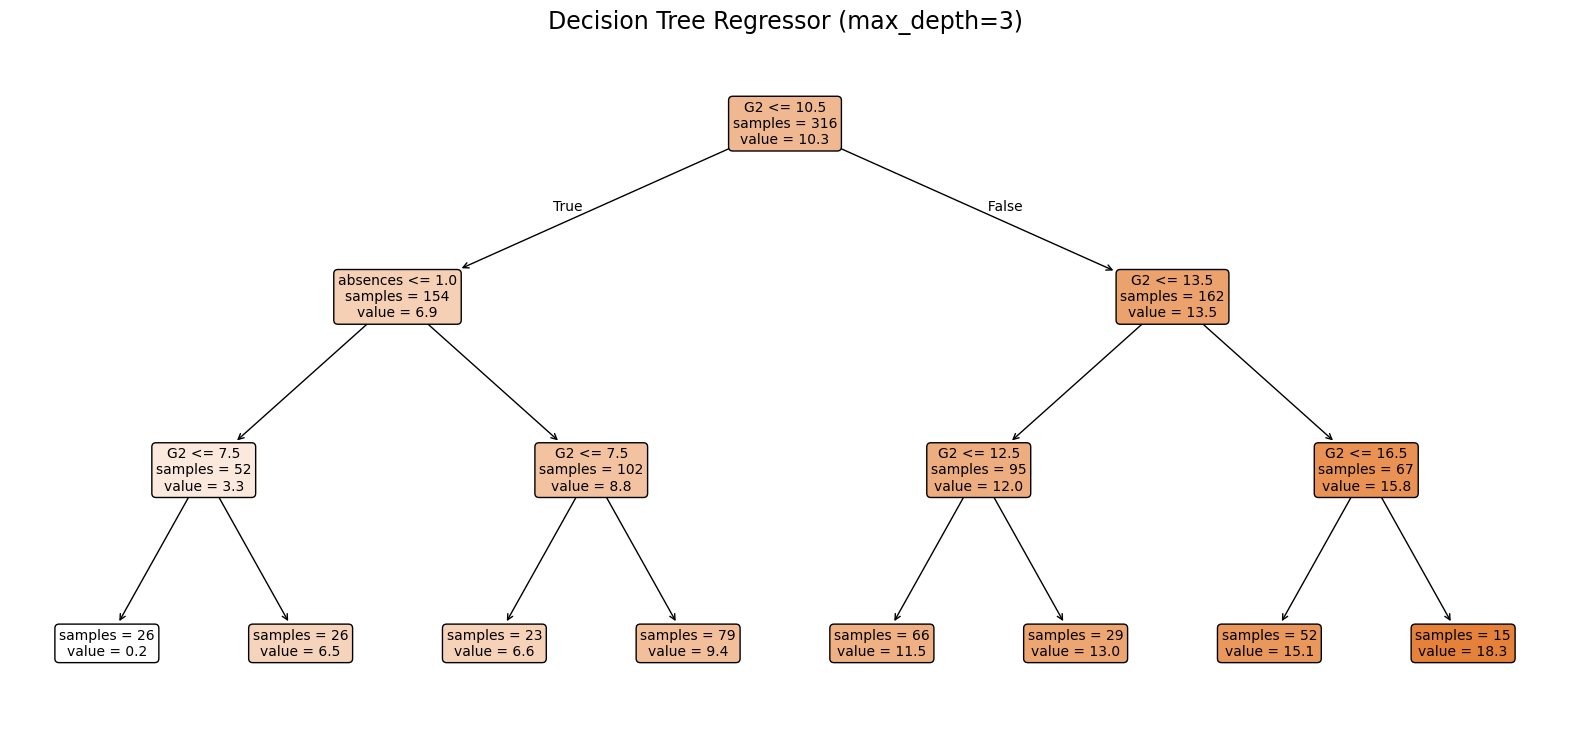

In [11]:
plt.figure(figsize=(20, 9))

plot_tree(
    tree,
    feature_names=features,
    filled=True,
    rounded=True,
    impurity=False,  # Hide the MSE formula to keep labels clean.
    precision=1,
    fontsize=10
)

plt.title("Decision Tree Regressor (max_depth=3)", fontsize=17)
plt.show()

## 8. Evaluate the predictions

We use **regression metrics**, because our output is a number.

- **MAE (mean absolute error):** On average, how many grade points are we off? **Lower is better.**
- **RMSE (root mean squared error):** Similar, but it penalizes big misses more. **Lower is better.**
- **R²:** How much better are we than always predicting the average grade? **1 is perfect; 0 is roughly equal to the average-grade baseline; negative is worse.**

Let's compare our tree with a very simple baseline that always predicts the average *training* grade.

In [12]:
# Baseline: always predict the average training grade.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

# How wrong is our simple baseline?
baseline_mae = mean_absolute_error(y_test, baseline_predictions)

# How wrong is our decision tree?
tree_mae = mean_absolute_error(y_test, tree_predictions)
tree_rmse = np.sqrt(mean_squared_error(y_test, tree_predictions))
tree_r2 = r2_score(y_test, tree_predictions)

print(f"Baseline MAE: {baseline_mae:.2f} grade points")
print(f"Tree MAE:     {tree_mae:.2f} grade points")
print(f"Tree RMSE:    {tree_rmse:.2f} grade points")
print(f"Tree R²:      {tree_r2:.2f}")

Baseline MAE: 3.65 grade points
Tree MAE:     1.31 grade points
Tree RMSE:    2.17 grade points
Tree R²:      0.77


### Actual grade vs. predicted grade

If predictions were perfect, every dot would lie on the dashed diagonal line. Dots farther away mean bigger errors.

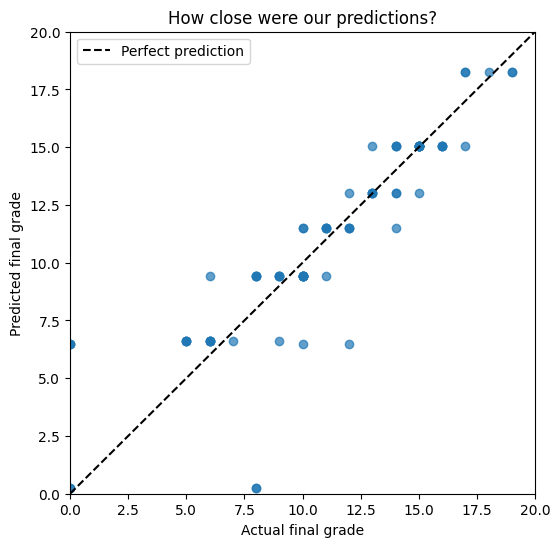

In [13]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, tree_predictions, alpha=0.7)
plt.plot([0, 20], [0, 20], "k--", label="Perfect prediction")
plt.xlim(0, 20)
plt.ylim(0, 20)
plt.xlabel("Actual final grade")
plt.ylabel("Predicted final grade")
plt.title("How close were our predictions?")
plt.legend()
plt.show()

## 9. Which features mattered most?

**Feature importance** measures how much each feature helped the tree reduce prediction error in its *training data*.

These scores add up to **1.0**. A high score means the tree used that feature to make useful splits. **It does not prove causation.**

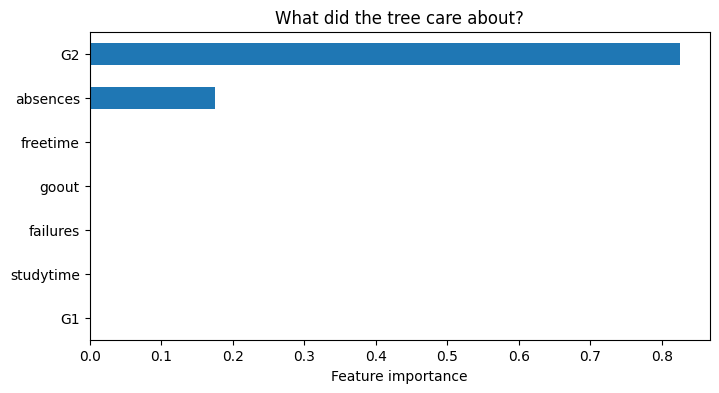

G2           0.825
absences     0.175
G1           0.000
studytime    0.000
failures     0.000
goout        0.000
freetime     0.000
dtype: float64


In [14]:
# Pair every feature name with its importance score.
importance = pd.Series(tree.feature_importances_, index=features)

# Put the largest importance at the top of the chart.
importance = importance.sort_values()

plt.figure(figsize=(8, 4))
importance.plot(kind="barh")
plt.xlabel("Feature importance")
plt.title("What did the tree care about?")
plt.show()

print(importance.sort_values(ascending=False).round(3))

## 10. Bonus: try a Random Forest Regressor

A **random forest** averages predictions from many different decision trees. It is often more accurate than one tiny tree, but harder to draw.

We'll try **100 trees** and compare the errors on the *same test students*.

In [21]:
# A forest of 100 trees, rather than one tree of depth 3.
forest = RandomForestRegressor(n_estimators=100, random_state=42)
forest.fit(X_train, y_train)
forest_predictions = forest.predict(X_test)

forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_predictions))
forest_r2 = r2_score(y_test, forest_predictions)

# How wrong is our decision tree?
print(f"Baseline MAE: {baseline_mae:.2f} grade points")
print('/'*33)
print(f"Tree MAE:     {tree_mae:.2f} grade points")
print(f"Tree RMSE:    {tree_rmse:.2f} grade points")
print(f"Tree R²:      {tree_r2:.2f}")


print('/'*33)
print(f"Random forest MAE:  {forest_mae:.2f}")
print(f"Random forest RMSE: {forest_rmse:.2f}")
print(f"Random forest R²:   {forest_r2:.2f}")

Baseline MAE: 3.65 grade points
/////////////////////////////////
Tree MAE:     1.31 grade points
Tree RMSE:    2.17 grade points
Tree R²:      0.77
/////////////////////////////////
Random forest MAE:  1.13
Random forest RMSE: 1.71
Random forest R²:   0.86


## 11. Confusion matrix: a **different** problem (Pass vs. Fail)

A confusion matrix cannot directly evaluate predictions like **12.7/20**. It needs **categories**.

So let's create a **separate decision tree classifier**, also with `max_depth=3`:

- **Fail (0):** Final grade below 10.
- **Pass (1):** Final grade 10 or higher.

We use the *same features and the same train/test split*, but now train the model to predict **Pass or Fail**, not an exact grade.

# Okay.  So G2 is by far the most important factor to determining G3.  But thats obvious....  Tell me something more interesting. 
### Remove G1 and G2, and try using interesting features like "Walc" weekend alcohol consumption. "
### Full list of features [see the data dict](https://archive.ics.uci.edu/dataset/320/student+performance)

# Student that comes up with the MOST INTERESTING finding gets a FULL WEEK homework pass and letter of rec from me. 
Some interesting features:
* "absences" - number of school absences (numeric: from 0 to 93)
* "Walc" - weekend alcohol consumption (numeric: from 1 - very low to 5 - very high)
* "goout" - going out with friends (numeric: from 1 - very low to 5 - very high)
* "reason" - reason to choose this school (nominal: close to 'home', school 'reputation', 'course' preference or 'other')
